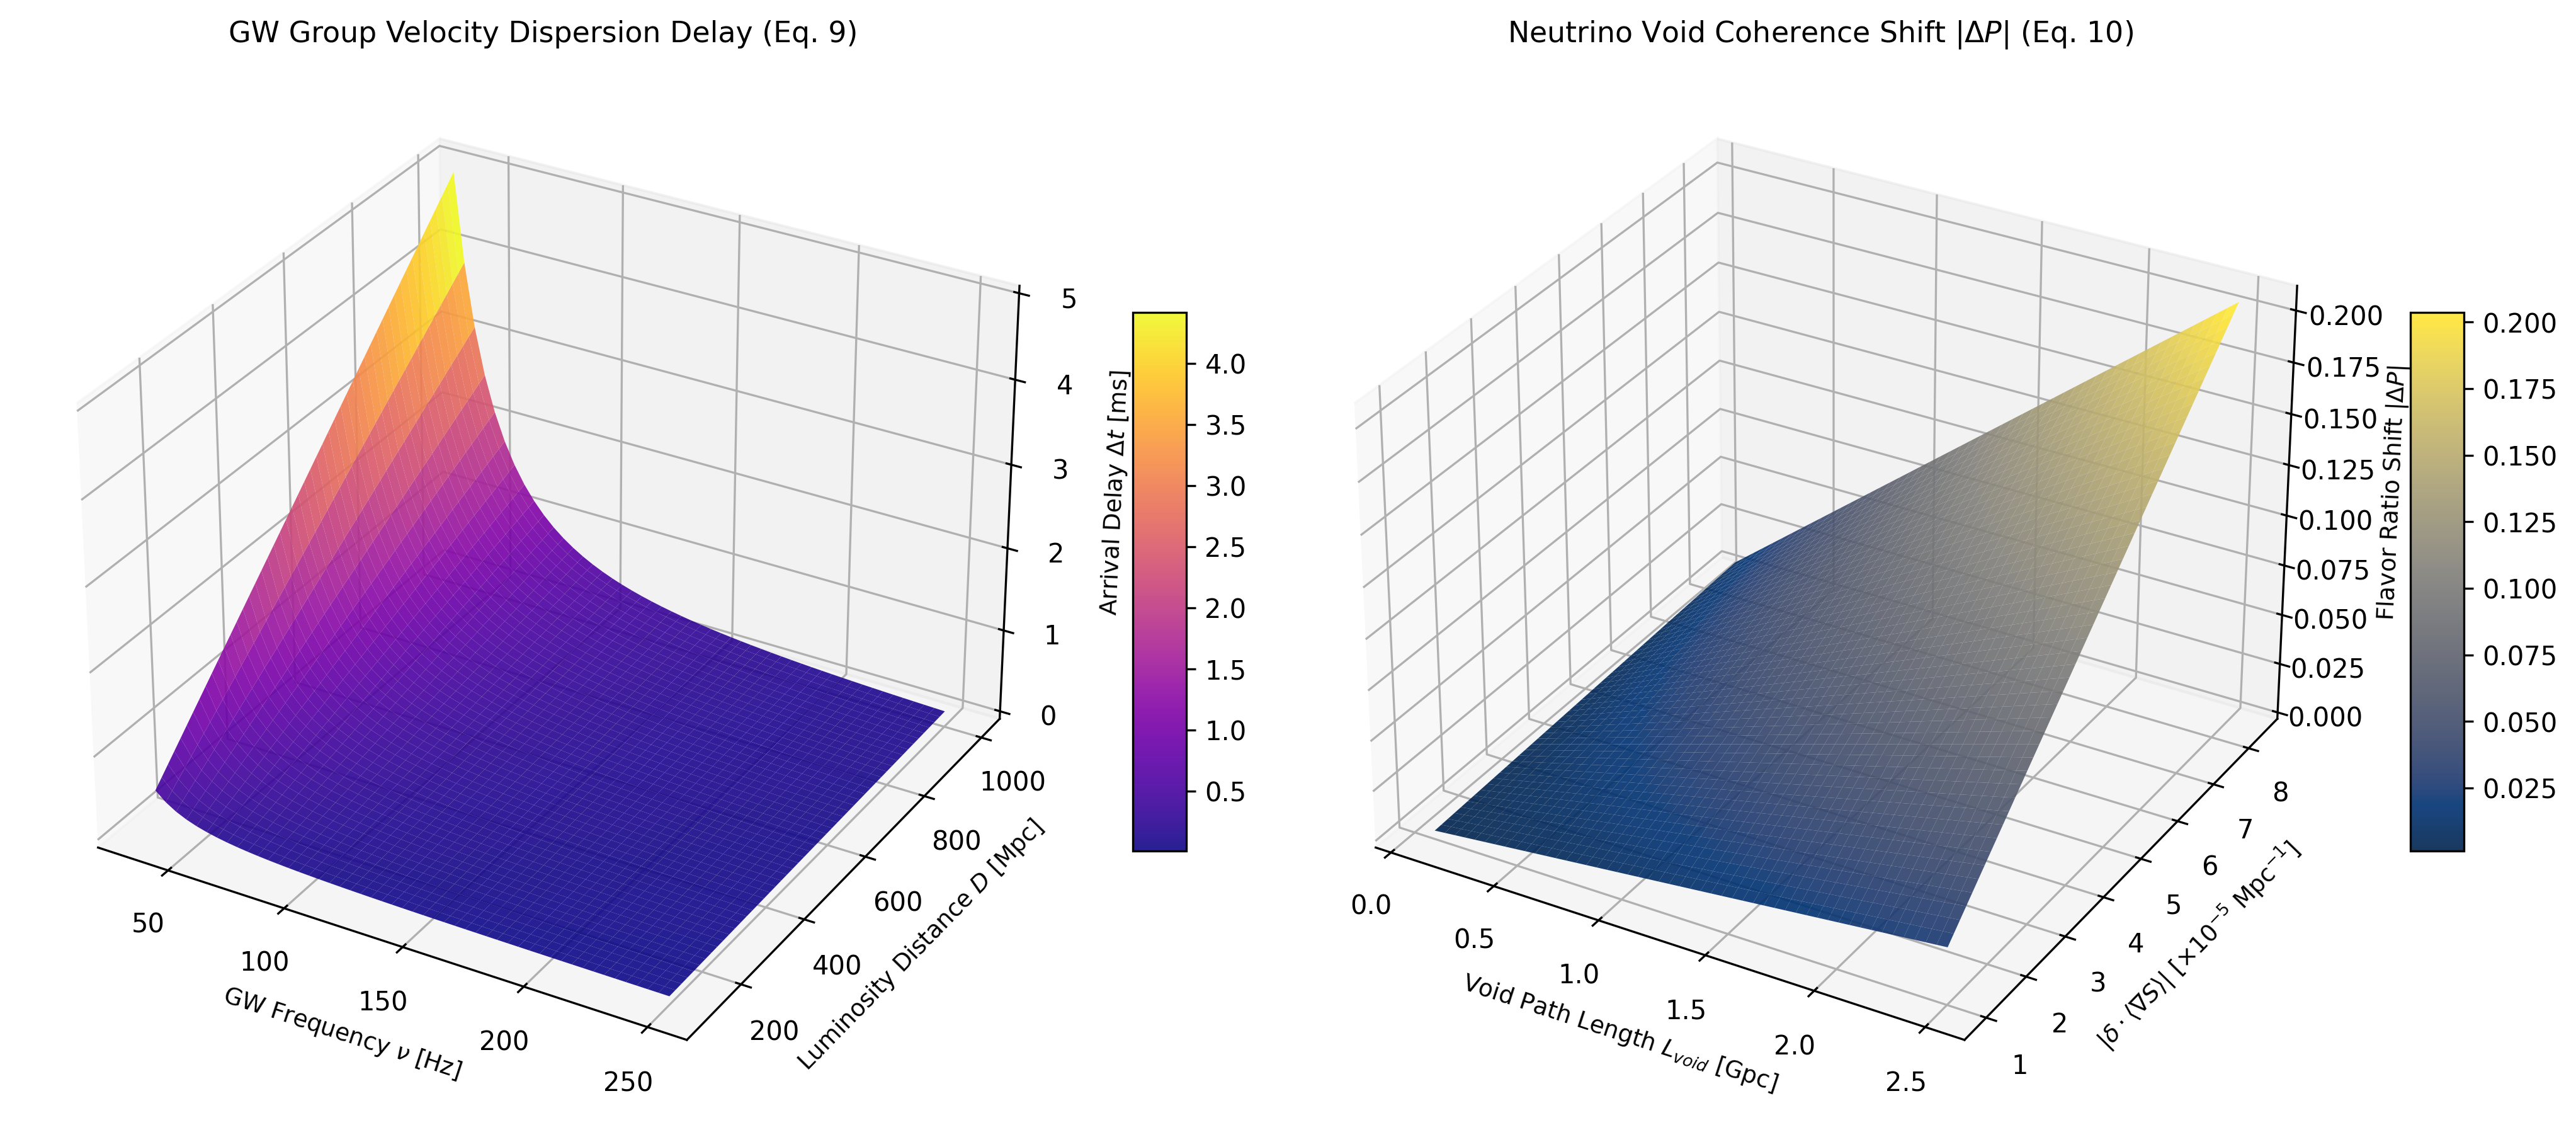

In [1]:

import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(14, 6), dpi=300)

# --- اللوحة الأولى: تشتت موجات الجاذبية (المعادلة 9 - LIGO/NANOGrav) ---
ax1 = fig.add_subplot(121, projection='3d')
freq = np.linspace(35, 250, 50)        # نطاق ترددات LIGO (Hz)
dist_mpc = np.linspace(100, 1000, 50)  # المسافة بالميجابارسك (Mpc)
F, D = np.meshgrid(freq, dist_mpc)

c = 2.998e8
mpc_to_m = 3.086e22
nu0 = 7.7e-9  # الحد الأعلى للتردد القطعي (7.7 nHz) من المعادلة 9
alpha = 1.0

# التأخير الزمني الناتج عن التشتت الصوتي بالمللي ثانية (ms)
delta_t_ms = ((D * mpc_to_m) / c) * (alpha * (nu0**2 / F**2)) * 1000

surf1 = ax1.plot_surface(F, D, delta_t_ms, cmap='plasma', alpha=0.9)
ax1.set_title('GW Group Velocity Dispersion Delay (Eq. 9)', fontsize=11)
ax1.set_xlabel('GW Frequency $\\nu$ [Hz]', fontsize=9)
ax1.set_ylabel('Luminosity Distance $D$ [Mpc]', fontsize=9)
ax1.set_zlabel('Arrival Delay $\\Delta t$ [ms]', fontsize=9)
fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10)

# --- اللوحة الثانية: فقدان ترابط النيوترينو في الفراغات (المعادلة 10 - IceCube) ---
ax2 = fig.add_subplot(122, projection='3d')
L_void = np.linspace(0.1, 2.5, 50)          # طول مسار الفراغ الكوني (Gpc)
grad_S = np.linspace(1e-5, 8.3e-5, 50)      # تدرج الطور الفعال (Mpc^-1)
L, G = np.meshgrid(L_void, grad_S)

# الانحراف الاحتمالي لنكهة النيوترينو |Delta P| (L_void محول إلى Mpc)
delta_P = (L * 1000.0) * G

surf2 = ax2.plot_surface(L, G * 1e5, delta_P, cmap='cividis', alpha=0.9)
ax2.set_title('Neutrino Void Coherence Shift $|\\Delta P|$ (Eq. 10)', fontsize=11)
ax2.set_xlabel('Void Path Length $L_{void}$ [Gpc]', fontsize=9)
ax2.set_ylabel('$|\\delta \\cdot \\langle\\nabla S\\rangle|$ [$\\times 10^{-5}$ Mpc$^{-1}$]', fontsize=9)
ax2.set_zlabel('Flavor Ratio Shift $|\\Delta P|$', fontsize=9)
fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10)

plt.tight_layout()
plt.savefig('sim2_3d_gw_neutrino.png', dpi=300)
plt.show()